In [7]:
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import tensorflow as tf

import matplotlib.pyplot as plt

np.set_printoptions(precision=2)

In [8]:
data = np.loadtxt('data_w3_ex1.csv', delimiter=',')
x = data[:,0]
y = data[:,1]
print(x.shape)
print(y.shape)

(50,)
(50,)


In [9]:
# convert to 2D arrays
x = np.expand_dims(x, axis=1) # column vector
y = np.expand_dims(y, axis=1) 
print(x.shape)
print(y.shape)

(50, 1)
(50, 1)


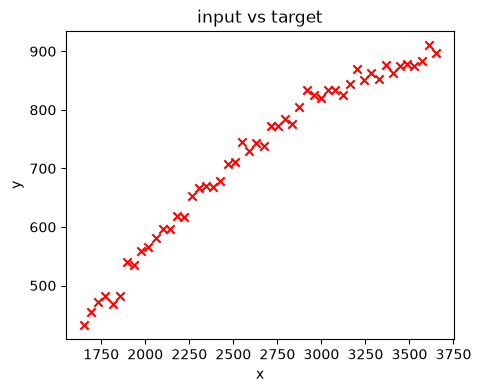

In [10]:
# plot the dataset
plt.figure(figsize=(5,4))
plt.scatter(x, y, marker='x', color='r')
plt.xlabel('x')
plt.ylabel('y')
plt.title('input vs target')
plt.show()

In [11]:
# Get 60% of the dataset as the training set. Put the remaining 40% in temporary variables: x_ and y_.
x_train, x_, y_train, y_ = train_test_split(x, y, test_size=0.4, random_state=1)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
x_cv, x_test, y_cv, y_test = train_test_split(x_, y_, test_size=0.5, random_state=1)

# delete temporary variables x_ and y_
del x_, y_

print(f"the shape of the training set (input) is: {x_train.shape}")
print(f"the shape of the training set (target) is: {y_train.shape}\n")
print(f"the shape of the cross validation set (input) is: {x_cv.shape}")
print(f"the shape of the cross validation set (target) is: {y_cv.shape}\n")
print(f"the shape of the test set (input) is: {x_test.shape}")
print(f"the shape of the test set (target) is: {y_test.shape}")

the shape of the training set (input) is: (30, 1)
the shape of the training set (target) is: (30, 1)

the shape of the cross validation set (input) is: (10, 1)
the shape of the cross validation set (target) is: (10, 1)

the shape of the test set (input) is: (10, 1)
the shape of the test set (target) is: (10, 1)


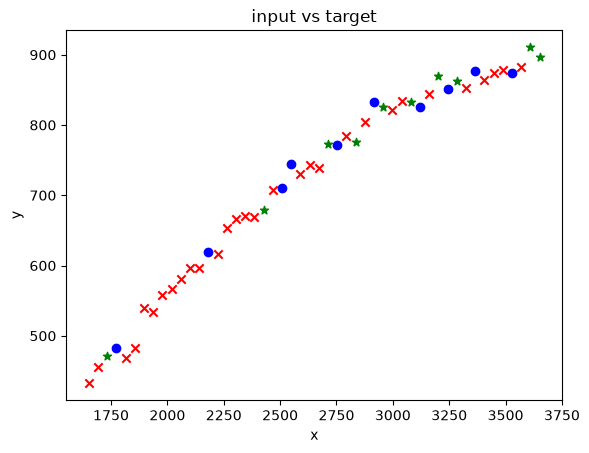

In [12]:
plt.scatter(x_train, y_train, marker='x', color='r', label='training')
plt.scatter(x_cv, y_cv, marker='o', color='b', label='cross-validation')
plt.scatter(x_test, y_test, marker='*', color='g', label='test')
plt.xlabel('x')
plt.ylabel('y')
plt.title('input vs target')
plt.show()

In [16]:
scaler_linear = StandardScaler()

X_train_scaled = scaler_linear.fit_transform(x_train) # fit computes mean, std from data. transform applies the learned parameters to data

print(f"Computed mean of the training set: {scaler_linear.mean_.squeeze():0.2f}")
print(f"Computed standard deviation of the training set: {scaler_linear.scale_.squeeze():0.2f}")

Computed mean of the training set: 2504.06
Computed standard deviation of the training set: 574.85


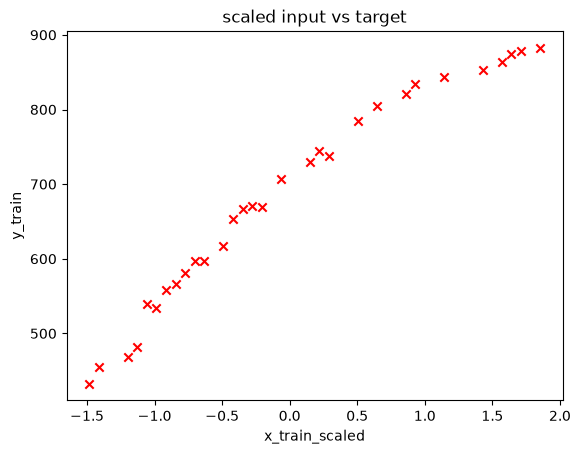

In [19]:
# plot the scaled dataset
# plt.figure(figsize=(5,4))
plt.scatter(X_train_scaled, y_train, marker='x', color='r')
plt.xlabel('x_train_scaled')
plt.ylabel('y_train')
plt.title('scaled input vs target')
plt.show()

In [22]:
print(f"{np.min(X_train_scaled):0.3f}")
print(f"{np.max(X_train_scaled):0.3f}")

-1.484
1.853


In [23]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[136.36]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[681.55]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.48]


In [26]:
linear_model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[136.36]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[681.55]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.48]


In [28]:
yhat = linear_model.predict(X_train_scaled)

# using scikit-learn's utility function and divide by 2
print(f"training MSE (using sklearn function): {mean_squared_error(y_train, yhat) / 2}")

# using for loop implementation
total_squared_error = 0
m = len(yhat)
for i in range(m):
    squared_error_i = (yhat[i] - y_train[i]) ** 2
    total_squared_error += squared_error_i
mse = total_squared_error / (2 * m)
print(f"training MSE (using for loop implementation): {mse.squeeze()}")

training MSE (using sklearn function): 406.19374192533155
training MSE (using for loop implementation): 406.19374192533155


In [29]:
# scale the cross-validation set using mean and std of training set
x_cv_scaled = scaler_linear.transform(x_cv)

print(f"mean used to scale the CV set: {scaler_linear.mean_.squeeze():0.2f}")
print(f"standard deviation used to scale the CV set: {scaler_linear.scale_.squeeze():0.2f}")

yhat = linear_model.predict(x_cv_scaled)

print(f"Cross validation MSE: {mean_squared_error(y_cv, yhat) / 2}")

mean used to scale the CV set: 2504.06
standard deviation used to scale the CV set: 574.85
Cross validation MSE: 551.7789026952216
